# ExitNet: Adaptive Early-Exit Inference for CNNs
## 1. Environment Setup

In [ ]:
#imports
import os
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split

from google.colab import drive

# Mount persistent Google Drive
drive.mount("/content/drive")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Persistent project directories
PROJECT_DIR = Path("/content/drive/MyDrive/APS360_ExitNet")

DATA_DIR = PROJECT_DIR / "data"
SPLIT_DIR = PROJECT_DIR / "splits"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"
CONFIG_DIR = PROJECT_DIR / "configs"

for folder in [
    DATA_DIR,
    SPLIT_DIR,
    CHECKPOINT_DIR,
    RESULT_DIR,
    FIGURE_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
GPU: Tesla T4
Project directory: /content/drive/MyDrive/APS360_ExitNet


In [ ]:
# Download CIFAR-100 to persistent storage
raw_train = datasets.CIFAR100(
    root=str(DATA_DIR),
    train=True,
    download=True
)

raw_test = datasets.CIFAR100(
    root=str(DATA_DIR),
    train=False,
    download=True
)

NUM_CLASSES = 100
NUM_VAL = 5000

# Save split indices so they never change between sessions
SPLIT_FILE = SPLIT_DIR / "cifar100_split_seed42.npz"

if SPLIT_FILE.exists():
    saved = np.load(SPLIT_FILE)

    train_indices = saved["train_indices"]
    val_indices = saved["val_indices"]

    print("Loaded existing split from Drive.")

else:
    all_indices = np.arange(len(raw_train))
    labels = np.array(raw_train.targets)

    train_indices, val_indices = train_test_split(
        all_indices,
        test_size=NUM_VAL,
        stratify=labels,
        random_state=SEED
    )

    np.savez_compressed(
        SPLIT_FILE,
        train_indices=train_indices,
        val_indices=val_indices
    )

    print("Created and saved new split.")

# Verify dataset sizes
assert len(train_indices) == 45000
assert len(val_indices) == 5000
assert len(raw_test) == 10000

assert len(np.intersect1d(train_indices, val_indices)) == 0

labels = np.array(raw_train.targets)

train_counts = np.bincount(labels[train_indices], minlength=100)
val_counts = np.bincount(labels[val_indices], minlength=100)

assert np.all(train_counts == 450)
assert np.all(val_counts == 50)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(raw_test))
print("Classes:", NUM_CLASSES)
print("Train samples per class:", np.unique(train_counts))
print("Validation samples per class:", np.unique(val_counts))

Loaded existing split from Drive.
Training samples: 45000
Validation samples: 5000
Test samples: 10000
Classes: 100
Train samples per class: [450]
Validation samples per class: [50]


In [ ]:
# Calculate normalization statistics from training data only

STATS_FILE = CONFIG_DIR / f"cifar100_stats_seed{SEED}.json"

if STATS_FILE.exists():
    with open(STATS_FILE, "r") as f:
        stats = json.load(f)

    CIFAR100_MEAN = tuple(stats["mean"])
    CIFAR100_STD = tuple(stats["std"])

    print("Loaded normalization statistics from Drive.")

else:
    print("Computing training-set mean and standard deviation...")

    channel_sum = np.zeros(3, dtype=np.float64)
    channel_squared_sum = np.zeros(3, dtype=np.float64)
    total_pixels = 0

    # Process in chunks to avoid excessive RAM usage
    CHUNK_SIZE = 1000

    for start in range(0, len(train_indices), CHUNK_SIZE):
        indices = train_indices[start:start + CHUNK_SIZE]

        # Original images: uint8 [0, 255]
        # Convert to floating point [0, 1]
        batch = raw_train.data[indices].astype(np.float64) / 255.0

        channel_sum += batch.sum(axis=(0, 1, 2))
        channel_squared_sum += (batch ** 2).sum(axis=(0, 1, 2))

        total_pixels += batch.shape[0] * batch.shape[1] * batch.shape[2]

    mean = channel_sum / total_pixels
    variance = channel_squared_sum / total_pixels - mean ** 2
    std = np.sqrt(np.maximum(variance, 0))

    CIFAR100_MEAN = tuple(mean.tolist())
    CIFAR100_STD = tuple(std.tolist())

    # Save statistics
    with open(STATS_FILE, "w") as f:
        json.dump({
            "seed": SEED,
            "num_training_images": len(train_indices),
            "mean": list(CIFAR100_MEAN),
            "std": list(CIFAR100_STD)
        }, f, indent=4)

    print("Computed and saved normalization statistics.")

print("Mean:", CIFAR100_MEAN)
print("Std:", CIFAR100_STD)


# Augmentation only for training
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD)
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD)
])


# Create datasets

train_full = datasets.CIFAR100(
    root=str(DATA_DIR),
    train=True,
    download=False,
    transform=train_transform
)

val_full = datasets.CIFAR100(
    root=str(DATA_DIR),
    train=True,
    download=False,
    transform=eval_transform
)

test_dataset = datasets.CIFAR100(
    root=str(DATA_DIR),
    train=False,
    download=False,
    transform=eval_transform
)

train_dataset = Subset(train_full, train_indices.tolist())
val_dataset = Subset(val_full, val_indices.tolist())


# Create DataLoaders

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Reserved for final evaluation
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# Sanity checks

images, labels = next(iter(train_loader))

assert images.shape[1:] == (3, 32, 32)
assert labels.min() >= 0 and labels.max() < 100

print("\nDataset Summary")
print("-------------------------------")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)


Loaded normalization statistics from Drive.
Mean: (0.5070556501906319, 0.486423455712146, 0.4405843258952887)
Std: (0.2672420444620094, 0.25633431814684415, 0.2760312956173254)

Dataset Summary
-------------------------------
Training samples: 45000
Validation samples: 5000
Test samples: 10000
Batch size: 128
Training batches: 352
Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Image dtype: torch.float32


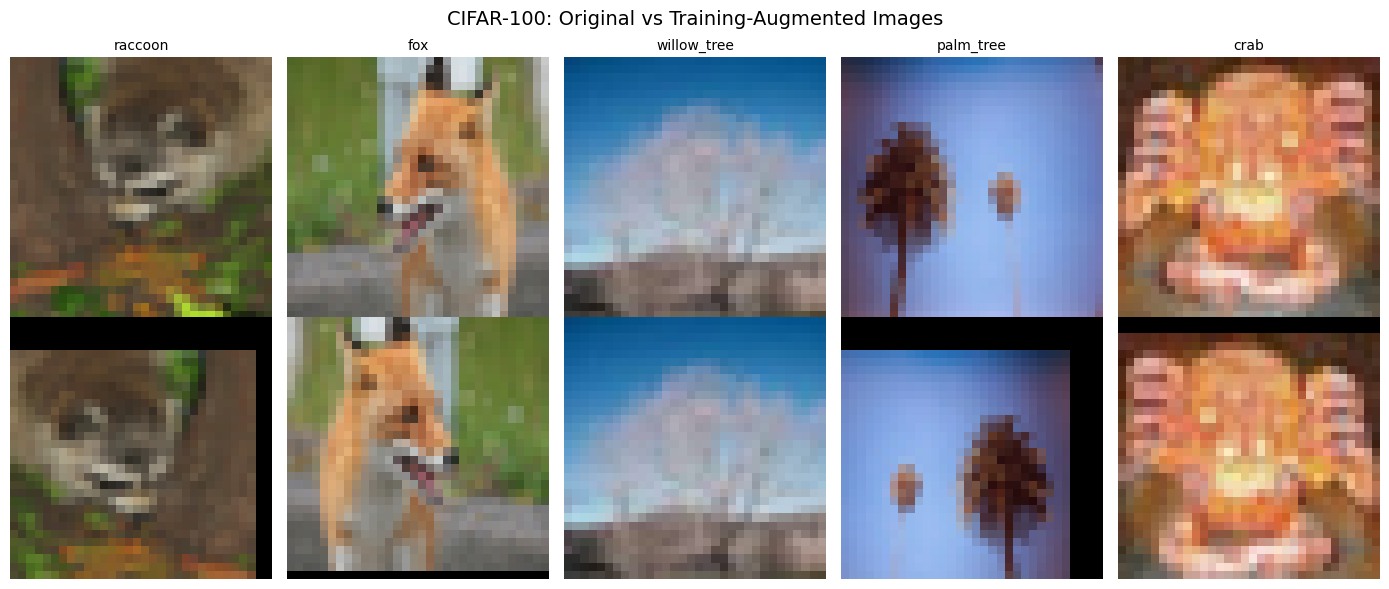

Figure saved to: /content/drive/MyDrive/APS360_ExitNet/figures/cifar100_preprocessing.png


In [ ]:

# Visualize Original and Augmented Training Images
rng = np.random.default_rng(SEED)

# Select 5 reproducible training examples
sample_indices = rng.choice(
    train_indices,
    size=5,
    replace=False
)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

# Tensors for reversing normalization for visualization
mean_tensor = torch.tensor(CIFAR100_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(CIFAR100_STD).view(3, 1, 1)

for col, idx in enumerate(sample_indices):

    idx = int(idx)

    # Original image
    original_img = raw_train.data[idx]
    label = raw_train.targets[idx]
    class_name = raw_train.classes[label]

    axes[0, col].imshow(original_img)
    axes[0, col].set_title(class_name, fontsize=10)
    axes[0, col].axis("off")

    # Augmented and normalized training image
    processed_img, _ = train_full[idx]

    # Reverse normalization for display only
    display_img = processed_img * std_tensor + mean_tensor
    display_img = display_img.clamp(0, 1)
    display_img = display_img.permute(1, 2, 0).numpy()

    axes[1, col].imshow(display_img)
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Augmented", fontsize=12)

fig.suptitle(
    "CIFAR-100: Original vs Training-Augmented Images",
    fontsize=14
)

plt.tight_layout()

figure_path = FIGURE_DIR / "cifar100_preprocessing.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path)


## 2. ExitNet Architecture

In [ ]:
# Basic Residual Block

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Adjust dimensions when channels/stride change
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = self.relu(out)

        return out


# Intermediate Classification Head

class ExitHead(nn.Module):
    def __init__(self, in_channels, num_classes=100):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=1,
                bias=False
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, num_classes)
        )

    def forward(self, x):
        return self.layers(x)


# Complete Multi-Exit Network

class ExitNet(nn.Module):
    def __init__(self, num_classes=100, base_channels=48):
        super().__init__()

        c = base_channels

        # Initial feature extraction
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, c, kernel_size=3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(c),
            nn.ReLU(inplace=True)
        )

        # Stage 1: 32x32 resolution
        self.stage1 = nn.Sequential(
            BasicBlock(c, c),
            BasicBlock(c, c)
        )

        self.exit1 = ExitHead(c, num_classes)

        # Stage 2: 16x16 resolution
        self.stage2 = nn.Sequential(
            BasicBlock(c, 2*c, stride=2),
            BasicBlock(2*c, 2*c)
        )

        self.exit2 = ExitHead(2*c, num_classes)

        # Stage 3: 8x8 resolution
        self.stage3 = nn.Sequential(
            BasicBlock(2*c, 4*c, stride=2),
            BasicBlock(4*c, 4*c)
        )

        # Full-depth classifier
        self.final_classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(4*c, num_classes)
        )

    def forward(self, x):
        # First stage and prediction
        x = self.stage1(self.stem(x))
        logits1 = self.exit1(x)

        # Second stage and prediction
        x = self.stage2(x)
        logits2 = self.exit2(x)

        # Third stage and final prediction
        x = self.stage3(x)
        logits3 = self.final_classifier(x)

        return logits1, logits2, logits3


# Instantiate the model
model = ExitNet(
    num_classes=NUM_CLASSES,
    base_channels=48
).to(DEVICE)

print("ExitNet initialized successfully!")
print("Device:", DEVICE)
print("Total parameters:",
      f"{sum(p.numel() for p in model.parameters()):,}")


ExitNet initialized successfully!
Device: cuda
Total parameters: 1,700,028


In [ ]:

# Architecture Verification

model.eval()

# Small batch from the actual CIFAR-100 DataLoader
sample_images = images[:4].to(DEVICE)

with torch.no_grad():

    x0 = model.stem(sample_images)
    x1 = model.stage1(x0)
    x2 = model.stage2(x1)
    x3 = model.stage3(x2)

    logits1, logits2, logits3 = model(sample_images)

print("Input:       ", tuple(sample_images.shape))
print("After stem:  ", tuple(x0.shape))
print("After stage1:", tuple(x1.shape))
print("After stage2:", tuple(x2.shape))
print("After stage3:", tuple(x3.shape))

print("\nClassification outputs")
print("Exit 1:", tuple(logits1.shape))
print("Exit 2:", tuple(logits2.shape))
print("Final: ", tuple(logits3.shape))

assert logits1.shape == (4, NUM_CLASSES)
assert logits2.shape == (4, NUM_CLASSES)
assert logits3.shape == (4, NUM_CLASSES)

print("\nAll architecture shape checks passed!")


Input:        (4, 3, 32, 32)
After stem:   (4, 48, 32, 32)
After stage1: (4, 48, 32, 32)
After stage2: (4, 96, 16, 16)
After stage3: (4, 192, 8, 8)

Classification outputs
Exit 1: (4, 100)
Exit 2: (4, 100)
Final:  (4, 100)

All architecture shape checks passed!


In [ ]:

# Multi-Exit Loss and Gradient Sanity Check

criterion = nn.CrossEntropyLoss()

EXIT_LOSS_WEIGHTS = (0.3, 0.3, 1.0)

def multi_exit_loss(outputs, targets):
    individual_losses = [
        criterion(logits, targets)
        for logits in outputs
    ]

    total_loss = sum(
        weight * loss
        for weight, loss in zip(
            EXIT_LOSS_WEIGHTS,
            individual_losses
        )
    )

    return total_loss, individual_losses


# Use a small real batch for testing
small_images = images[:8].to(DEVICE)
small_labels = labels[:8].to(DEVICE)

model.eval()
model.zero_grad(set_to_none=True)

# Forward pass
outputs = model(small_images)

# Calculate the three losses
total_loss, individual_losses = multi_exit_loss(
    outputs, small_labels
)

print("Exit 1 loss:", individual_losses[0].item())
print("Exit 2 loss:", individual_losses[1].item())
print("Final loss: ", individual_losses[2].item())
print("Total loss: ", total_loss.item())

# Backpropagation
total_loss.backward()

# Verify that gradients reached the shared backbone
assert model.stem[0].weight.grad is not None

# Verify that gradients reached every classifier
assert model.exit1.layers[-1].weight.grad is not None
assert model.exit2.layers[-1].weight.grad is not None
assert model.final_classifier[-1].weight.grad is not None

assert torch.isfinite(total_loss).item()

print("\nBackward pass successful!")
print("All three exits receive gradients.")

# Clear test gradients
model.zero_grad(set_to_none=True)
model.train()


Exit 1 loss: 4.61731481552124
Exit 2 loss: 4.633069038391113
Final loss:  4.572484016418457
Total loss:  7.347599029541016

Backward pass successful!
All three exits receive gradients.


ExitNet(
  (stem): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (stage1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Identity()
      (relu): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(48, 

## 3. Model Training and Checkpointing

In [ ]:

# Training Infrastructure

import time
import copy

# Training configuration

TOTAL_EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 5e-4
USE_AMP = DEVICE.type == "cuda"

TRAINING_CONFIG = {
    "seed": SEED,
    "epochs": TOTAL_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "base_channels": 48,
    "num_classes": NUM_CLASSES,
    "exit_loss_weights": list(EXIT_LOSS_WEIGHTS)
}

# Dedicated checkpoint directory
MODEL_DIR = CHECKPOINT_DIR / "exitnet"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

LAST_CHECKPOINT = MODEL_DIR / "last.pt"
BEST_CHECKPOINT = MODEL_DIR / "best.pt"

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Reduce learning rate gradually
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=TOTAL_EPOCHS
)

# Automatic mixed precision
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)


# Save and load checkpoints

def save_checkpoint(epoch, history, best_val_acc, is_best=False):

    checkpoint = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "best_val_acc": best_val_acc,
        "history": history,
        "config": TRAINING_CONFIG,

        # Random states for reproducible resumption
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
        )
    }

    # Save to a temporary file first
    # This reduces the risk of damaging last.pt if
    # saving is interrupted.
    temp_path = LAST_CHECKPOINT.with_suffix(".pt.tmp")

    torch.save(checkpoint, temp_path)
    os.replace(temp_path, LAST_CHECKPOINT)

    if is_best:
        best_temp = BEST_CHECKPOINT.with_suffix(".pt.tmp")
        torch.save(checkpoint, best_temp)
        os.replace(best_temp, BEST_CHECKPOINT)


def load_checkpoint():

    if not LAST_CHECKPOINT.exists():
        print("No checkpoint found. Starting from epoch 1.")
        return 0, [], 0.0

    # Only load checkpoints created by your own trusted code.
    checkpoint = torch.load(
        LAST_CHECKPOINT,
        map_location=DEVICE,
        weights_only=False
    )

    if checkpoint["config"] != TRAINING_CONFIG:
        raise ValueError(
            "Training configuration differs from saved checkpoint. "
            "Review the configuration before resuming."
        )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    scaler.load_state_dict(checkpoint["scaler_state"])

    random.setstate(checkpoint["python_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    torch.set_rng_state(checkpoint["torch_rng"].cpu())

    if (
        torch.cuda.is_available()
        and checkpoint["cuda_rng"] is not None
    ):
        torch.cuda.set_rng_state_all([state.cpu() for state in checkpoint["cuda_rng"]])

    epoch = checkpoint["epoch"]
    history = checkpoint["history"]
    best_val_acc = checkpoint["best_val_acc"]

    print(f"Resumed from completed epoch {epoch}")
    print(f"Best validation accuracy: {best_val_acc:.2f}%")

    return epoch, history, best_val_acc


# Train or validate for one epoch

def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = [0, 0, 0]
    total_samples = 0

    for batch_images, batch_labels in loader:

        batch_images = batch_images.to(
            DEVICE, non_blocking=True
        )
        batch_labels = batch_labels.to(
            DEVICE, non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(batch_images)

                loss, individual_losses = multi_exit_loss(
                    outputs, batch_labels
                )

            if training:
                if not torch.isfinite(loss).item():
                    raise RuntimeError("Non-finite training loss.")

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        batch_size = batch_labels.size(0)
        total_samples += batch_size

        total_loss += loss.item() * batch_size

        for i, logits in enumerate(outputs):
            predictions = logits.argmax(dim=1)

            total_correct[i] += (
                predictions == batch_labels
            ).sum().item()

    avg_loss = total_loss / total_samples

    accuracies = [
        100.0 * correct / total_samples
        for correct in total_correct
    ]

    return avg_loss, accuracies


# Main training function

def train_exitnet(epochs_to_run):

    start_epoch, history, best_val_acc = load_checkpoint()

    if start_epoch >= TOTAL_EPOCHS:
        print("Training already completed.")
        return history

    end_epoch = min(
        start_epoch + epochs_to_run,
        TOTAL_EPOCHS
    )

    for epoch in range(start_epoch + 1, end_epoch + 1):

        start_time = time.time()

        lr = optimizer.param_groups[0]["lr"]

        # Training
        train_loss, train_acc = run_epoch(
            train_loader, training=True
        )

        # Validation
        val_loss, val_acc = run_epoch(
            val_loader, training=False
        )

        scheduler.step()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.time() - start_time

        # Track best final-exit accuracy
        is_best = val_acc[2] > best_val_acc

        if is_best:
            best_val_acc = val_acc[2]

        # Record results
        record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,

            "train_exit1_acc": train_acc[0],
            "train_exit2_acc": train_acc[1],
            "train_final_acc": train_acc[2],

            "val_exit1_acc": val_acc[0],
            "val_exit2_acc": val_acc[1],
            "val_final_acc": val_acc[2],

            "learning_rate": lr,
            "epoch_seconds": elapsed
        }

        history.append(record)

        # Save after every completed epoch
        save_checkpoint(
            epoch,
            history,
            best_val_acc,
            is_best=is_best
        )

        print(
            f"Epoch {epoch:02d}/{TOTAL_EPOCHS} | "
            f"Loss: {train_loss:.4f}/{val_loss:.4f} | "
            f"Train Acc: {train_acc[2]:.2f}% | "
            f"Val Acc: {val_acc[2]:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

        print(
            f"  Validation exits: "
            f"E1={val_acc[0]:.2f}%  "
            f"E2={val_acc[1]:.2f}%  "
            f"Final={val_acc[2]:.2f}%"
        )

        if is_best:
            print("  New best model saved!")

    print("\nCheckpoint location:", LAST_CHECKPOINT)
    print("Best-model location:", BEST_CHECKPOINT)

    return history


print("Training infrastructure initialized!")
print("Device:", DEVICE)
print("Mixed precision enabled:", USE_AMP)
print("Checkpoint directory:", MODEL_DIR)

Training infrastructure initialized!
Device: cuda
Mixed precision enabled: True
Checkpoint directory: /content/drive/MyDrive/APS360_ExitNet/checkpoints/exitnet


In [ ]:
# Start training
history = train_exitnet(epochs_to_run=1)

No checkpoint found. Starting from epoch 1.
Epoch 01/30 | Loss: 6.2348/5.7477 | Train Acc: 11.08% | Val Acc: 16.46% | Time: 22.7s
  Validation exits: E1=10.08%  E2=13.88%  Final=16.46%
  New best model saved!

Checkpoint location: /content/drive/MyDrive/APS360_ExitNet/checkpoints/exitnet/last.pt
Best-model location: /content/drive/MyDrive/APS360_ExitNet/checkpoints/exitnet/best.pt


In [ ]:
print("Last checkpoint:", LAST_CHECKPOINT.exists())
print("Best checkpoint:", BEST_CHECKPOINT.exists())

Last checkpoint: True
Best checkpoint: True


In [ ]:
# Continue training
history = train_exitnet(epochs_to_run=29)

Resumed from completed epoch 1
Best validation accuracy: 16.46%
Epoch 02/30 | Loss: 5.3109/5.1406 | Train Acc: 21.58% | Val Acc: 24.48% | Time: 22.1s
  Validation exits: E1=12.90%  E2=20.10%  Final=24.48%
  New best model saved!
Epoch 03/30 | Loss: 4.7504/4.9136 | Train Acc: 28.76% | Val Acc: 26.12% | Time: 24.4s
  Validation exits: E1=16.70%  E2=22.36%  Final=26.12%
  New best model saved!
Epoch 04/30 | Loss: 4.3590/4.5869 | Train Acc: 34.09% | Val Acc: 31.80% | Time: 24.6s
  Validation exits: E1=17.28%  E2=27.48%  Final=31.80%
  New best model saved!
Epoch 05/30 | Loss: 4.0535/4.1128 | Train Acc: 38.35% | Val Acc: 37.02% | Time: 23.1s
  Validation exits: E1=22.06%  E2=31.62%  Final=37.02%
  New best model saved!
Epoch 06/30 | Loss: 3.7856/4.0634 | Train Acc: 42.17% | Val Acc: 38.68% | Time: 23.6s
  Validation exits: E1=20.90%  E2=32.94%  Final=38.68%
  New best model saved!
Epoch 07/30 | Loss: 3.5511/3.8093 | Train Acc: 46.08% | Val Acc: 43.94% | Time: 23.7s
  Validation exits: E1=24

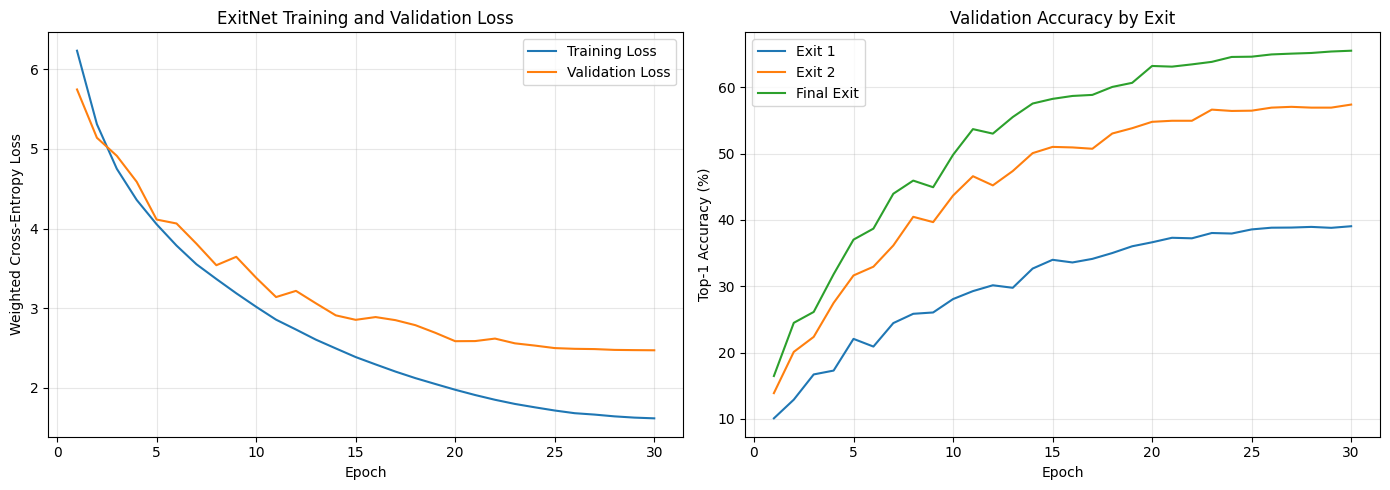

Saved learning curves: /content/drive/MyDrive/APS360_ExitNet/figures/exitnet_learning_curves.png
Saved training history: /content/drive/MyDrive/APS360_ExitNet/results/exitnet_training_history.json

Best validation checkpoint:
Epoch: 30
Exit 1: 39.04%
Exit 2: 57.38%
Final: 65.50%


In [ ]:

# Plotting ExitNet Training Results

epochs = [h["epoch"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Training and validation loss

axes[0].plot(
    epochs,
    [h["train_loss"] for h in history],
    label="Training Loss"
)

axes[0].plot(
    epochs,
    [h["val_loss"] for h in history],
    label="Validation Loss"
)

axes[0].set_title("ExitNet Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Validation accuracy at each exit

for key, label in [
    ("val_exit1_acc", "Exit 1"),
    ("val_exit2_acc", "Exit 2"),
    ("val_final_acc", "Final Exit")
]:
    axes[1].plot(
        epochs,
        [h[key] for h in history],
        label=label
    )

axes[1].set_title("Validation Accuracy by Exit")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Top-1 Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

figure_path = FIGURE_DIR / "exitnet_learning_curves.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save numerical training history as JSON
history_path = RESULT_DIR / "exitnet_training_history.json"

with open(history_path, "w") as f:
    json.dump(history, f, indent=4)

print("Saved learning curves:", figure_path)
print("Saved training history:", history_path)

# Summarize best epoch
best_record = max(
    history,
    key=lambda h: h["val_final_acc"]
)

print("\nBest validation checkpoint:")
print("Epoch:", best_record["epoch"])
print("Exit 1:", f'{best_record["val_exit1_acc"]:.2f}%')
print("Exit 2:", f'{best_record["val_exit2_acc"]:.2f}%')
print("Final:", f'{best_record["val_final_acc"]:.2f}%')


## 4. Early-Exit Inference and Evaluation

In [ ]:

# Extract Validation Predictions From Best Checkpoint

# Load our best trained model
best_checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state"])
model = model.to(DEVICE)
model.eval()

print("Loaded best model from epoch:", best_checkpoint["epoch"])

# Store logits for each exit
all_logits = [[], [], []]
all_labels = []

with torch.inference_mode():

    for batch_images, batch_labels in val_loader:

        batch_images = batch_images.to(DEVICE)

        outputs = model(batch_images)

        for i, logits in enumerate(outputs):
            all_logits[i].append(logits.float().cpu())

        all_labels.append(batch_labels.cpu())

# Shape: (3, 5000, 100)
val_logits = torch.stack([
    torch.cat(exit_logits, dim=0)
    for exit_logits in all_logits
])

# Shape: (5000,)
val_labels = torch.cat(all_labels)

assert val_logits.shape == (3, 5000, NUM_CLASSES)
assert val_labels.shape == (5000,)

# Save predictions for future sessions
VAL_PREDICTIONS_FILE = (
    RESULT_DIR / f"validation_logits_seed{SEED}.pt"
)

torch.save({
    "logits": val_logits,
    "labels": val_labels,
    "val_indices": torch.as_tensor(val_indices.copy()),
    "checkpoint_epoch": best_checkpoint["epoch"]
}, VAL_PREDICTIONS_FILE)

# Evaluate each exit independently
val_probs = torch.softmax(val_logits, dim=-1)

# Each row corresponds to one exit
val_confidences, val_predictions = val_probs.max(dim=-1)

for i in range(3):
    accuracy = (
        (val_predictions[i] == val_labels)
        .float()
        .mean()
        .item() * 100
    )

    avg_confidence = (
        val_confidences[i].mean().item() * 100
    )

    print(
        f"Exit {i+1}: "
        f"Accuracy={accuracy:.2f}% | "
        f"Mean confidence={avg_confidence:.2f}%"
    )

print("\nPredictions saved to:", VAL_PREDICTIONS_FILE)

Loaded best model from epoch: 30
Exit 1: Accuracy=39.08% | Mean confidence=36.21%
Exit 2: Accuracy=57.40% | Mean confidence=59.77%
Exit 3: Accuracy=65.50% | Mean confidence=74.68%

Predictions saved to: /content/drive/MyDrive/APS360_ExitNet/results/validation_logits_seed42.pt


In [ ]:

# Confidence Threshold Baseline

import pandas as pd

def evaluate_threshold(threshold):

    # Start by assigning every image to the final exit
    chosen_exits = torch.full(
        (len(val_labels),),
        2,
        dtype=torch.long
    )

    # Exit 1 if sufficiently confident
    exit1_mask = val_confidences[0] >= threshold

    # Otherwise, try Exit 2
    exit2_mask = (
        (~exit1_mask)
        & (val_confidences[1] >= threshold)
    )

    chosen_exits[exit1_mask] = 0
    chosen_exits[exit2_mask] = 1

    # Select the actual predicted class at chosen exit
    chosen_predictions = val_predictions.gather(
        dim=0,
        index=chosen_exits.unsqueeze(0)
    ).squeeze(0)

    accuracy = (
        (chosen_predictions == val_labels)
        .float()
        .mean()
        .item() * 100
    )

    counts = torch.bincount(
        chosen_exits,
        minlength=3
    )

    total = len(val_labels)

    return {
        "threshold": threshold,
        "val_accuracy": accuracy,
        "exit1_pct": 100 * counts[0].item() / total,
        "exit2_pct": 100 * counts[1].item() / total,
        "final_pct": 100 * counts[2].item() / total
    }


# Sweep confidence thresholds
thresholds = [
    0.0, 0.1, 0.2, 0.3, 0.4, 0.5,
    0.6, 0.7, 0.8, 0.9, 0.95,
    0.98, 0.99, 1.01
]

results = [
    evaluate_threshold(t)
    for t in thresholds
]

threshold_df = pd.DataFrame(results)

display(threshold_df.round(2))

# Save results to Google Drive
threshold_path = RESULT_DIR / "threshold_sweep.csv"

threshold_df.to_csv(
    threshold_path,
    index=False
)

print("Saved:", threshold_path)

,threshold,val_accuracy,exit1_pct,exit2_pct,final_pct
0,0.00,39.08,100.00,0.00,0.00
1,0.10,39.78,97.18,2.82,0.00
2,0.20,46.40,72.38,24.54,3.08
3,0.30,53.64,49.64,36.94,13.42
4,0.40,58.22,33.96,39.50,26.54
5,0.50,61.50,23.22,38.02,38.76
6,0.60,63.66,15.78,33.48,50.74
7,0.70,64.62,10.66,29.04,60.30
8,0.80,65.20,6.20,23.60,70.20
9,0.90,65.30,2.96,17.28,79.76


Saved: /content/drive/MyDrive/APS360_ExitNet/results/threshold_sweep.csv


Computational cost per image:

full_depth  : 237.28 M MACs (100.0% of baseline)
exit1       : 107.50 M MACs (45.3% of baseline)
exit2       : 204.24 M MACs (86.1% of baseline)
exit3       : 279.76 M MACs (117.9% of baseline)


,threshold,val_accuracy,avg_mmacs,compute_saved_pct
0,0.00,39.08,107.50,54.69
1,0.10,39.78,110.23,53.54
2,0.20,46.40,136.55,42.45
3,0.30,53.64,166.35,29.89
4,0.40,58.22,191.43,19.32
5,0.50,61.50,211.05,11.05
6,0.60,63.66,227.29,4.21
7,0.70,64.62,239.46,-0.92
8,0.80,65.20,251.26,-5.89
9,0.90,65.30,261.61,-10.26


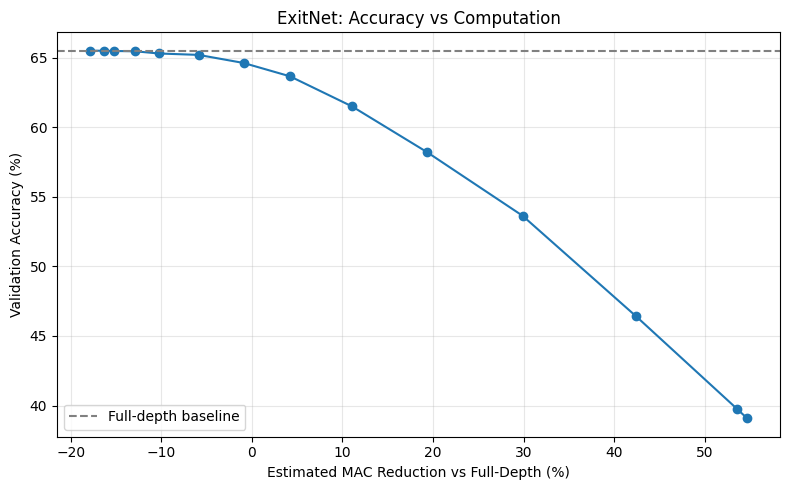

In [ ]:

# Measure Computational Cost of Each Inference Path

def count_path_macs(network, path):
    """
    Valid paths:
        full_depth: Backbone + final classifier only
        exit1: Stem + Stage 1 + Head 1
        exit2: Exit 1 path + Stage 2 + Head 2
        exit3: Exit 2 path + Stage 3 + Final classifier
    """
    network.eval()
    total_macs = 0
    hooks = []

    def count_hook(module, inputs, output):
        nonlocal total_macs

        if isinstance(module, nn.Conv2d):
            batch, out_c, out_h, out_w = output.shape
            kh, kw = module.kernel_size

            total_macs += (
                batch * out_c * out_h * out_w
                * (module.in_channels // module.groups)
                * kh * kw
            )

        elif isinstance(module, nn.Linear):
            total_macs += output.numel() * module.in_features

    for module in network.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            hooks.append(
                module.register_forward_hook(count_hook)
            )

    try:
        with torch.inference_mode():
            x = torch.zeros(1, 3, 32, 32, device=DEVICE)

            x = network.stage1(network.stem(x))

            if path != "full_depth":
                network.exit1(x)

            if path == "exit1":
                return total_macs

            x = network.stage2(x)

            if path != "full_depth":
                network.exit2(x)

            if path == "exit2":
                return total_macs

            x = network.stage3(x)
            network.final_classifier(x)

            if path not in ("exit3", "full_depth"):
                raise ValueError(f"Unknown path: {path}")

            return total_macs

    finally:
        for hook in hooks:
            hook.remove()


paths = ["full_depth", "exit1", "exit2", "exit3"]

path_macs = {
    path: count_path_macs(model, path)
    for path in paths
}

baseline_macs = path_macs["full_depth"]

print("Computational cost per image:\n")

for name, macs in path_macs.items():
    print(
        f"{name:12s}: {macs / 1e6:.2f} M MACs "
        f"({macs / baseline_macs * 100:.1f}% of baseline)"
    )

# Add estimated compute savings to threshold results
threshold_df["avg_mmacs"] = (
    threshold_df["exit1_pct"] / 100 * path_macs["exit1"]
    + threshold_df["exit2_pct"] / 100 * path_macs["exit2"]
    + threshold_df["final_pct"] / 100 * path_macs["exit3"]
) / 1e6

threshold_df["compute_saved_pct"] = (
    1 - threshold_df["avg_mmacs"] * 1e6 / baseline_macs
) * 100

display(
    threshold_df[
        [
            "threshold",
            "val_accuracy",
            "avg_mmacs",
            "compute_saved_pct"
        ]
    ].round(2)
)

# Save the updated results
threshold_df.to_csv(
    RESULT_DIR / "threshold_sweep_with_compute.csv",
    index=False
)

with open(RESULT_DIR / "path_macs.json", "w") as f:
    json.dump(path_macs, f, indent=4)

# Plot the accuracy-computation trade-off
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["compute_saved_pct"],
    threshold_df["val_accuracy"],
    marker="o"
)

baseline_accuracy = (
    (val_predictions[2] == val_labels)
    .float().mean().item() * 100
)

plt.axhline(
    baseline_accuracy,
    linestyle="--",
    color="gray",
    label="Full-depth baseline"
)

plt.xlabel("Estimated MAC Reduction vs Full-Depth (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("ExitNet: Accuracy vs Computation")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "accuracy_vs_compute.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# True Dynamic Early-Exit Inference

@torch.inference_mode()
def dynamic_predict(network, batch_images, threshold=0.8):

    network.eval()

    batch_size = batch_images.size(0)
    device = batch_images.device

    predictions = torch.empty(
        batch_size, dtype=torch.long, device=device
    )

    exit_indices = torch.empty(
        batch_size, dtype=torch.long, device=device
    )

    # Stage 1

    features1 = network.stage1(
        network.stem(batch_images)
    )

    logits1 = network.exit1(features1)

    confidence1 = torch.softmax(
        logits1.float(), dim=1
    ).max(dim=1).values

    stop1 = confidence1 >= threshold

    predictions[stop1] = logits1[stop1].argmax(dim=1)
    exit_indices[stop1] = 0

    # Remaining images
    remaining1 = torch.nonzero(
        ~stop1, as_tuple=True
    )[0]

    if remaining1.numel() == 0:
        return predictions, exit_indices

    # Stage 2

    features2 = network.stage2(
        features1[remaining1]
    )

    logits2 = network.exit2(features2)

    confidence2 = torch.softmax(
        logits2.float(), dim=1
    ).max(dim=1).values

    stop2 = confidence2 >= threshold

    original_indices2 = remaining1[stop2]

    predictions[original_indices2] = (
        logits2[stop2].argmax(dim=1)
    )

    exit_indices[original_indices2] = 1

    remaining2 = torch.nonzero(
        ~stop2, as_tuple=True
    )[0]

    if remaining2.numel() == 0:
        return predictions, exit_indices

    # Stage 3: Final classifier

    features3 = network.stage3(
        features2[remaining2]
    )

    logits3 = network.final_classifier(features3)

    original_indices3 = remaining1[remaining2]

    predictions[original_indices3] = (
        logits3.argmax(dim=1)
    )

    exit_indices[original_indices3] = 2

    return predictions, exit_indices


print("Dynamic early-exit inference implemented.")


Dynamic early-exit inference implemented.


In [ ]:
# Validate Dynamic Early-Exit Inference

model.eval()

for threshold in [0.6, 0.8, 1.01]:

    dynamic_predictions = []
    dynamic_exits = []

    for batch_images, _ in val_loader:
        batch_images = batch_images.to(DEVICE)

        preds, exits = dynamic_predict(
            model, batch_images, threshold
        )

        dynamic_predictions.append(preds.cpu())
        dynamic_exits.append(exits.cpu())

    dynamic_predictions = torch.cat(dynamic_predictions)
    dynamic_exits = torch.cat(dynamic_exits)

    # Reproduce the cached selection policy
    cached_exits = torch.full(
        (len(val_labels),), 2, dtype=torch.long
    )

    stop1 = val_confidences[0] >= threshold
    stop2 = (~stop1) & (val_confidences[1] >= threshold)

    cached_exits[stop1] = 0
    cached_exits[stop2] = 1

    cached_predictions = val_predictions.gather(
        0, cached_exits.unsqueeze(0)
    ).squeeze(0)

    prediction_mismatches = (
        dynamic_predictions != cached_predictions
    ).sum().item()

    routing_mismatches = (
        dynamic_exits != cached_exits
    ).sum().item()

    accuracy = (
        (dynamic_predictions == val_labels)
        .float().mean().item() * 100
    )

    exit_distribution = (
        torch.bincount(dynamic_exits, minlength=3)
        .float() / len(val_labels) * 100
    )

    print(f"\nThreshold: {threshold}")
    print(f"Dynamic accuracy: {accuracy:.2f}%")
    print(f"Prediction mismatches: {prediction_mismatches}")
    print(f"Routing mismatches: {routing_mismatches}")
    print(
        "Exit distribution:",
        [round(x, 2) for x in exit_distribution.tolist()]
    )

    if threshold == 1.01:
        assert torch.all(dynamic_exits == 2)

print("\nDynamic inference verification complete.")


Threshold: 0.6
Dynamic accuracy: 63.66%
Prediction mismatches: 0
Routing mismatches: 0
Exit distribution: [15.78, 33.48, 50.74]

Threshold: 0.8
Dynamic accuracy: 65.20%
Prediction mismatches: 0
Routing mismatches: 0
Exit distribution: [6.2, 23.6, 70.2]

Threshold: 1.01
Dynamic accuracy: 65.50%
Prediction mismatches: 0
Routing mismatches: 0
Exit distribution: [0.0, 0.0, 100.0]

Dynamic inference verification complete.


In [ ]:

# Collect Training Predictions for MLP Controller

# Use the best trained CNN
model.load_state_dict(best_checkpoint["model_state"])
model.to(DEVICE)
model.eval()

CONTROLLER_DATA_FILE = (
    RESULT_DIR / f"controller_train_logits_seed{SEED}_epoch{best_checkpoint['epoch']}.pt"
)

if CONTROLLER_DATA_FILE.exists():

    cached = torch.load(
        CONTROLLER_DATA_FILE,
        map_location="cpu",
        weights_only=True
    )

    controller_train_logits = cached["logits"]
    controller_train_labels = cached["labels"]

    print("Loaded cached training predictions from Drive.")

else:

    # Same images as CNN training, but without random augmentation
    controller_dataset = Subset(
        val_full,
        train_indices.tolist()
    )

    controller_loader = DataLoader(
        controller_dataset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    collected_logits = [[], [], []]
    collected_labels = []

    with torch.inference_mode():

        for batch_images, batch_labels in controller_loader:

            batch_images = batch_images.to(DEVICE)

            outputs = model(batch_images)

            for i, logits in enumerate(outputs):
                collected_logits[i].append(
                    logits.float().cpu()
                )

            collected_labels.append(batch_labels)

    controller_train_logits = torch.stack([
        torch.cat(parts, dim=0)
        for parts in collected_logits
    ])

    controller_train_labels = torch.cat(
        collected_labels
    )

    torch.save({
        "logits": controller_train_logits,
        "labels": controller_train_labels,
        "checkpoint_epoch": best_checkpoint["epoch"],
        "seed": SEED
    }, CONTROLLER_DATA_FILE)

    print("Computed and saved controller-training predictions.")

assert controller_train_logits.shape == (3, 45000, NUM_CLASSES)
assert controller_train_labels.shape == (45000,)

print("Logit shape:", controller_train_logits.shape)
print("Label shape:", controller_train_labels.shape)
print("Saved to:", CONTROLLER_DATA_FILE)

Computed and saved controller-training predictions.
Logit shape: torch.Size([3, 45000, 100])
Label shape: torch.Size([45000])
Saved to: /content/drive/MyDrive/APS360_ExitNet/results/controller_train_logits_seed42_epoch30.pt


In [ ]:

# Train Compute-Aware MLP Controller

import math

CONTROLLER_LAMBDA = 0.1
CONTROLLER_FILE = MODEL_DIR / "controller_mlp.pt"

# Feature extraction

def gate_features(logits, exit_idx):

    probs = torch.softmax(logits.float(), dim=-1)
    top2 = probs.topk(2, dim=-1).values

    confidence = top2[:, 0]
    second_confidence = top2[:, 1]
    margin = confidence - second_confidence

    entropy = -(
        probs * probs.clamp_min(1e-12).log()
    ).sum(dim=-1) / math.log(NUM_CLASSES)

    stage_indicator = torch.full_like(
        confidence, float(exit_idx)
    )

    current_path = "exit1" if exit_idx == 0 else "exit2"

    remaining_cost = (
        path_macs["exit3"] - path_macs[current_path]
    ) / baseline_macs

    cost_feature = torch.full_like(
        confidence, remaining_cost
    )

    return torch.stack([
        confidence,
        second_confidence,
        margin,
        entropy,
        stage_indicator,
        cost_feature
    ], dim=-1)


# Shape: (45000, 2, 6)
controller_features = torch.stack([
    gate_features(controller_train_logits[0], 0),
    gate_features(controller_train_logits[1], 1)
], dim=1)


# Derive cost-aware oracle targets

correct = (
    controller_train_logits.argmax(dim=-1)
    == controller_train_labels.unsqueeze(0)
).float()

costs = torch.tensor([
    path_macs["exit1"],
    path_macs["exit2"],
    path_macs["exit3"]
], dtype=torch.float32) / baseline_macs

rewards = (
    correct - CONTROLLER_LAMBDA * costs[:, None]
)

# Gate 1: stop vs best possible downstream exit
stop1 = rewards[0] >= torch.maximum(
    rewards[1], rewards[2]
)

# Gate 2: stop vs final exit
stop2 = rewards[1] >= rewards[2]

# Shape: (45000, 2)
controller_targets = torch.stack([
    stop1.float(),
    stop2.float()
], dim=1)

print("Gate 1 oracle stop rate:",
      f"{stop1.float().mean().item() * 100:.2f}%")

print("Gate 2 oracle stop rate:",
      f"{stop2.float().mean().item() * 100:.2f}%")


# Define controller neural network

class ExitController(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(6, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


controller = ExitController().to(DEVICE)

print("Controller parameters:",
      sum(p.numel() for p in controller.parameters()))


# Train or load existing controller

if CONTROLLER_FILE.exists():

    saved = torch.load(
        CONTROLLER_FILE,
        map_location="cpu",
        weights_only=True
    )

    assert saved["seed"] == SEED
    assert saved["backbone_epoch"] == best_checkpoint["epoch"]
    assert saved["lambda"] == CONTROLLER_LAMBDA

    controller.load_state_dict(saved["state_dict"])
    print("Loaded trained controller from Drive.")

else:

    # Split by original image, not individual gate samples
    n_images = len(controller_train_labels)

    generator = torch.Generator().manual_seed(SEED + 17)
    permutation = torch.randperm(n_images, generator=generator)

    n_fit = int(0.85 * n_images)

    fit_indices = permutation[:n_fit]
    dev_indices = permutation[n_fit:]

    fit_dataset = torch.utils.data.TensorDataset(
        controller_features[fit_indices].reshape(-1, 6),
        controller_targets[fit_indices].reshape(-1)
    )

    fit_loader = DataLoader(
        fit_dataset,
        batch_size=2048,
        shuffle=True
    )

    dev_features = (
        controller_features[dev_indices]
        .reshape(-1, 6)
        .to(DEVICE)
    )

    dev_targets = (
        controller_targets[dev_indices]
        .reshape(-1)
        .to(DEVICE)
    )

    gate_optimizer = torch.optim.AdamW(
        controller.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    gate_criterion = nn.BCEWithLogitsLoss()

    best_dev_loss = float("inf")
    best_state = None

    for epoch in range(1, 21):

        controller.train()
        train_loss_sum = 0.0
        train_count = 0

        for xb, yb in fit_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            gate_optimizer.zero_grad(set_to_none=True)

            logits = controller(xb)
            loss = gate_criterion(logits, yb)

            loss.backward()
            gate_optimizer.step()

            train_loss_sum += loss.item() * len(yb)
            train_count += len(yb)

        controller.eval()

        with torch.inference_mode():
            dev_logits = controller(dev_features)
            dev_loss = gate_criterion(
                dev_logits, dev_targets
            ).item()

        if dev_loss < best_dev_loss:
            best_dev_loss = dev_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in controller.state_dict().items()
            }

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d}/20 | "
                f"Train BCE: {train_loss_sum/train_count:.4f} | "
                f"Dev BCE: {dev_loss:.4f}"
            )

    controller.load_state_dict(best_state)

    torch.save({
        "state_dict": best_state,
        "lambda": CONTROLLER_LAMBDA,
        "seed": SEED,
        "backbone_epoch": best_checkpoint["epoch"],
        "input_dim": 6,
        "best_dev_loss": best_dev_loss
    }, CONTROLLER_FILE)

    print("Controller trained and saved!")

controller.eval()

print("Controller checkpoint:", CONTROLLER_FILE)

Gate 1 oracle stop rate: 53.36%
Gate 2 oracle stop rate: 78.69%
Controller parameters: 769
Epoch 01/20 | Train BCE: 0.6709 | Dev BCE: 0.6373
Epoch 05/20 | Train BCE: 0.5146 | Dev BCE: 0.5097
Epoch 10/20 | Train BCE: 0.5123 | Dev BCE: 0.5086
Epoch 15/20 | Train BCE: 0.5120 | Dev BCE: 0.5085
Epoch 20/20 | Train BCE: 0.5119 | Dev BCE: 0.5091
Controller trained and saved!
Controller checkpoint: /content/drive/MyDrive/APS360_ExitNet/checkpoints/exitnet/controller_mlp.pt


Validation accuracy at fixed compute budgets:


,MAC_budget_M,confidence_accuracy,controller_accuracy
0,170,53.64,53.52
1,190,53.64,56.56
2,210,58.22,60.64
3,230,63.66,63.76
4,240,64.62,64.50
5,250,64.62,64.96


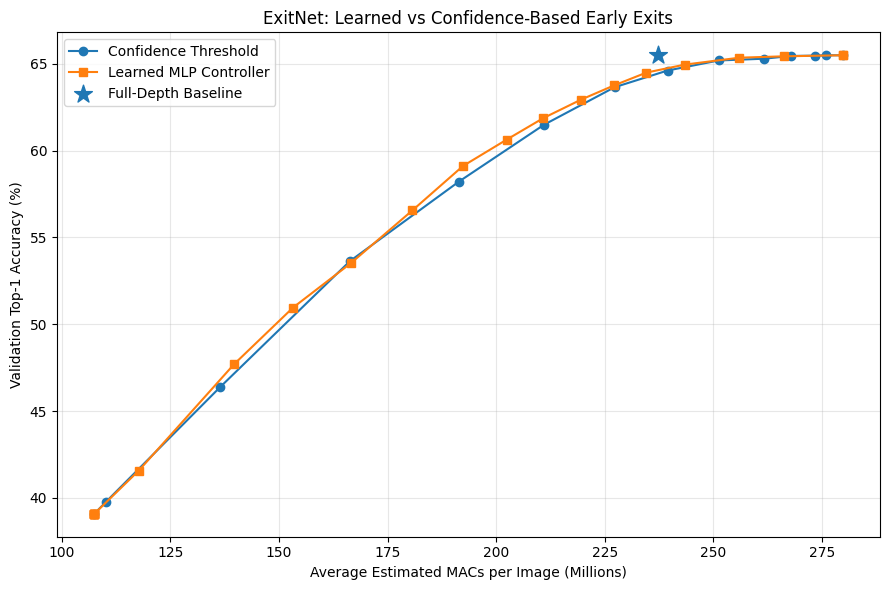


Best controller configuration within 2 pp:
threshold              0.800000
val_accuracy          63.760000
avg_mmacs            227.121225
compute_saved_pct      4.279692
exit1_pct             13.960000
exit2_pct             37.860000
final_pct             48.180000


In [ ]:
# Evaluate Learned Controller

controller.eval()

with torch.inference_mode():

    gate_scores = torch.stack([
        torch.sigmoid(
            controller(
                gate_features(val_logits[0], 0).to(DEVICE)
            )
        ).cpu(),

        torch.sigmoid(
            controller(
                gate_features(val_logits[1], 1).to(DEVICE)
            )
        ).cpu()
    ])

# Approximate MLP MACs: 6->32->16->1
GATE_MACS = 6*32 + 32*16 + 16*1


def evaluate_controller(threshold):

    exits = torch.full(
        (len(val_labels),), 2, dtype=torch.long
    )

    stop1 = gate_scores[0] >= threshold
    stop2 = (~stop1) & (gate_scores[1] >= threshold)

    exits[stop1] = 0
    exits[stop2] = 1

    predictions = val_predictions.gather(
        0, exits.unsqueeze(0)
    ).squeeze(0)

    accuracy = (
        (predictions == val_labels)
        .float().mean().item() * 100
    )

    counts = torch.bincount(exits, minlength=3)
    n = len(val_labels)

    # Include the cost of executing the MLP gates
    total_macs = (
        counts[0].item() * path_macs["exit1"]
        + counts[1].item() * path_macs["exit2"]
        + counts[2].item() * path_macs["exit3"]
        + n * GATE_MACS
        + (counts[1] + counts[2]).item() * GATE_MACS
    )

    avg_mmacs = total_macs / n / 1e6

    return {
        "threshold": threshold,
        "val_accuracy": accuracy,
        "avg_mmacs": avg_mmacs,
        "compute_saved_pct": (
            1 - total_macs / n / baseline_macs
        ) * 100,
        "exit1_pct": counts[0].item() / n * 100,
        "exit2_pct": counts[1].item() / n * 100,
        "final_pct": counts[2].item() / n * 100
    }


gate_thresholds = (
    [0.0]
    + list(np.linspace(0.05, 0.95, 19))
    + [0.975, 0.99, 1.01]
)

controller_df = pd.DataFrame([
    evaluate_controller(t)
    for t in gate_thresholds
])

controller_df.to_csv(
    RESULT_DIR / "controller_sweep.csv",
    index=False
)


# Compare best achievable accuracy at fixed MAC budgets

comparison = []

for budget in [170, 190, 210, 230, 240, 250]:

    confidence_candidates = threshold_df[
        threshold_df["avg_mmacs"] <= budget
    ]

    controller_candidates = controller_df[
        controller_df["avg_mmacs"] <= budget
    ]

    comparison.append({
        "MAC_budget_M": budget,
        "confidence_accuracy": (
            confidence_candidates["val_accuracy"].max()
            if len(confidence_candidates) else np.nan
        ),
        "controller_accuracy": (
            controller_candidates["val_accuracy"].max()
            if len(controller_candidates) else np.nan
        )
    })

comparison_df = pd.DataFrame(comparison)

print("Validation accuracy at fixed compute budgets:")
display(comparison_df.round(2))

comparison_df.to_csv(
    RESULT_DIR / "controller_vs_confidence.csv",
    index=False
)


# Plot both accuracy-compute curves

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["avg_mmacs"],
    threshold_df["val_accuracy"],
    marker="o",
    label="Confidence Threshold"
)

plt.plot(
    controller_df["avg_mmacs"],
    controller_df["val_accuracy"],
    marker="s",
    label="Learned MLP Controller"
)

plt.scatter(
    [baseline_macs / 1e6],
    [baseline_accuracy],
    marker="*",
    s=180,
    label="Full-Depth Baseline",
    zorder=5
)

plt.xlabel("Average Estimated MACs per Image (Millions)")
plt.ylabel("Validation Top-1 Accuracy (%)")
plt.title("ExitNet: Learned vs Confidence-Based Early Exits")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "controller_vs_confidence.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Find configurations within 2 percentage points
# of full-depth accuracy, with positive compute savings.
eligible = controller_df[
    (controller_df["val_accuracy"] >= baseline_accuracy - 2.0)
    & (controller_df["avg_mmacs"] < baseline_macs / 1e6)
]

if len(eligible):
    best_tradeoff = eligible.loc[
        eligible["compute_saved_pct"].idxmax()
    ]

    print("\nBest controller configuration within 2 pp:")
    print(best_tradeoff.to_string())

else:
    print(
        "\nNo controller configuration currently achieves "
        "both positive compute savings and <=2 pp "
        "validation accuracy loss."
    )

## 5. Learned Dynamic Inference and Latency

In [ ]:

# True Dynamic Inference With Learned Controller

@torch.inference_mode()
def dynamic_predict_controller(
    network,
    gate,
    batch_images,
    threshold=0.8
):
    network.eval()
    gate.eval()

    batch_size = batch_images.size(0)
    device = batch_images.device

    predictions = torch.empty(
        batch_size, dtype=torch.long, device=device
    )

    exit_indices = torch.empty(
        batch_size, dtype=torch.long, device=device
    )

    # Stage 1

    features1 = network.stage1(
        network.stem(batch_images)
    )

    logits1 = network.exit1(features1)

    # Current prediction features -> learned stop score
    scores1 = torch.sigmoid(
        gate(gate_features(logits1, exit_idx=0))
    )

    stop1 = scores1 >= threshold

    predictions[stop1] = logits1[stop1].argmax(dim=1)
    exit_indices[stop1] = 0

    remaining1 = torch.nonzero(
        ~stop1, as_tuple=True
    )[0]

    if remaining1.numel() == 0:
        return predictions, exit_indices

    # Stage 2: Only images that did not exit

    features2 = network.stage2(
        features1[remaining1]
    )

    logits2 = network.exit2(features2)

    scores2 = torch.sigmoid(
        gate(gate_features(logits2, exit_idx=1))
    )

    stop2 = scores2 >= threshold

    original_indices2 = remaining1[stop2]

    predictions[original_indices2] = (
        logits2[stop2].argmax(dim=1)
    )
    exit_indices[original_indices2] = 1

    remaining2 = torch.nonzero(
        ~stop2, as_tuple=True
    )[0]

    if remaining2.numel() == 0:
        return predictions, exit_indices

    # Stage 3: Remaining difficult images

    features3 = network.stage3(
        features2[remaining2]
    )

    logits3 = network.final_classifier(features3)

    original_indices3 = remaining1[remaining2]

    predictions[original_indices3] = (
        logits3.argmax(dim=1)
    )

    exit_indices[original_indices3] = 2

    return predictions, exit_indices


print("Learned dynamic inference implemented!")

Learned dynamic inference implemented!


In [ ]:

# Validate Learned Dynamic Inference

CONTROLLER_THRESHOLD = 0.8

model.eval()
controller.eval()

dynamic_predictions = []
dynamic_exits = []

with torch.inference_mode():

    for batch_images, _ in val_loader:

        batch_images = batch_images.to(DEVICE)

        predictions, exits = dynamic_predict_controller(
            model,
            controller,
            batch_images,
            threshold=CONTROLLER_THRESHOLD
        )

        dynamic_predictions.append(predictions.cpu())
        dynamic_exits.append(exits.cpu())

dynamic_predictions = torch.cat(dynamic_predictions)
dynamic_exits = torch.cat(dynamic_exits)

# Reconstruct routing from cached MLP scores
cached_exits = torch.full(
    (len(val_labels),), 2, dtype=torch.long
)

stop1 = gate_scores[0] >= CONTROLLER_THRESHOLD
stop2 = (
    (~stop1)
    & (gate_scores[1] >= CONTROLLER_THRESHOLD)
)

cached_exits[stop1] = 0
cached_exits[stop2] = 1

cached_predictions = val_predictions.gather(
    0, cached_exits.unsqueeze(0)
).squeeze(0)

prediction_mismatches = (
    dynamic_predictions != cached_predictions
).sum().item()

routing_mismatches = (
    dynamic_exits != cached_exits
).sum().item()

dynamic_accuracy = (
    (dynamic_predictions == val_labels)
    .float().mean().item() * 100
)

counts = torch.bincount(dynamic_exits, minlength=3)
exit_percentages = counts.float() / len(val_labels) * 100

# Average MACs including MLP
n = len(val_labels)

total_macs = (
    counts[0].item() * path_macs["exit1"]
    + counts[1].item() * path_macs["exit2"]
    + counts[2].item() * path_macs["exit3"]
    + n * GATE_MACS
    + (counts[1] + counts[2]).item() * GATE_MACS
)

avg_mmacs = total_macs / n / 1e6

print("Learned Controller Dynamic Inference")
print("------------------------------------")
print(f"Threshold: {CONTROLLER_THRESHOLD}")
print(f"Validation accuracy: {dynamic_accuracy:.2f}%")
print(f"Average MACs: {avg_mmacs:.2f} M")
print(f"Compute saved: {(1-total_macs/n/baseline_macs)*100:.2f}%")

print("\nExit distribution:")
for i, pct in enumerate(exit_percentages):
    print(f"  Exit {i+1}: {pct.item():.2f}%")

print("\nConsistency verification:")
print("Prediction mismatches:", prediction_mismatches)
print("Routing mismatches:", routing_mismatches)

if prediction_mismatches == 0 and routing_mismatches == 0:
    print("PASS: Dynamic and cached inference agree.")
else:
    print("Investigate mismatches before reporting final results.")

# Persist results and predictions
torch.save({
    "predictions": dynamic_predictions,
    "exit_indices": dynamic_exits,
    "labels": val_labels,
    "threshold": CONTROLLER_THRESHOLD,
    "accuracy": dynamic_accuracy,
    "avg_mmacs": avg_mmacs
}, RESULT_DIR / "learned_dynamic_validation.pt")

Learned Controller Dynamic Inference
------------------------------------
Threshold: 0.8
Validation accuracy: 63.76%
Average MACs: 227.12 M
Compute saved: 4.28%

Exit distribution:
  Exit 1: 13.96%
  Exit 2: 37.86%
  Exit 3: 48.18%

Consistency verification:
Prediction mismatches: 0
Routing mismatches: 0
PASS: Dynamic and cached inference agree.


,policy,mean_ms,median_ms,std_ms,speedup_x
0,Confidence 0.60,10.819,11.598,4.115,0.931
1,Full-depth,10.071,9.466,2.760,1.000
2,Learned MLP 0.80,10.348,12.034,2.892,0.973


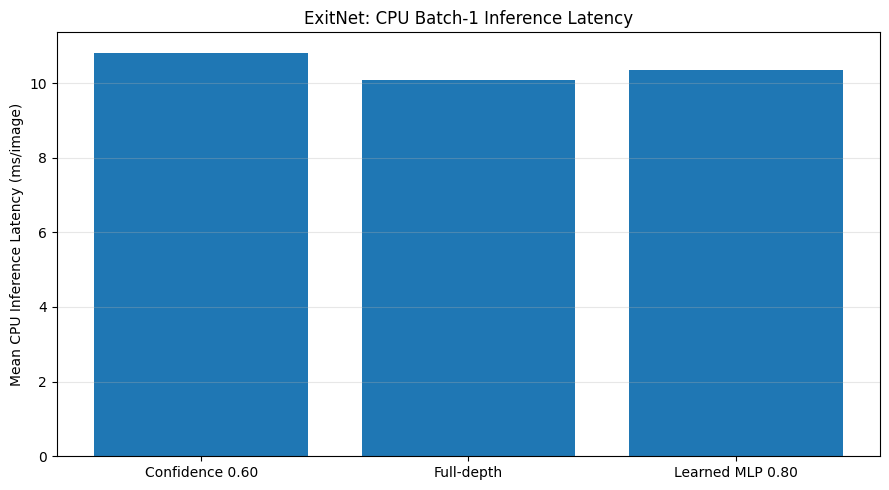

Latency results saved to Google Drive.


In [ ]:
# CPU Inference Latency Benchmark

import time
import copy

# Independent CPU copies; original GPU models remain unchanged
cpu_model = copy.deepcopy(model).cpu().eval()
cpu_controller = copy.deepcopy(controller).cpu().eval()

@torch.inference_mode()
def full_depth_predict(network, x):
    features = network.stage1(network.stem(x))
    features = network.stage2(features)
    features = network.stage3(features)

    logits = network.final_classifier(features)

    return logits.argmax(dim=1)


# Select reproducible validation samples
rng = np.random.default_rng(SEED + 123)
sample_ids = rng.choice(
    len(val_dataset),
    size=60,
    replace=False
)

cpu_samples = [
    val_dataset[int(i)][0].unsqueeze(0)
    for i in sample_ids
]

policies = {
    "Full-depth": lambda x: full_depth_predict(
        cpu_model, x
    ),
    "Confidence 0.60": lambda x: dynamic_predict(
        cpu_model, x, threshold=0.60
    ),
    "Learned MLP 0.80": lambda x: dynamic_predict_controller(
        cpu_model, cpu_controller, x,
        threshold=0.80
    )
}

latency_records = []

# Control CPU threading for consistent comparison
original_threads = torch.get_num_threads()

try:
    torch.set_num_threads(2)

    with torch.inference_mode():

        for policy_name, predict_fn in policies.items():

            # Warmup
            for x in cpu_samples[:5]:
                predict_fn(x)

            timings = []

            for x in cpu_samples:

                start = time.perf_counter()
                output = predict_fn(x)
                elapsed_ms = (
                    time.perf_counter() - start
                ) * 1000

                timings.append(elapsed_ms)

            for sample_id, latency in zip(sample_ids, timings):
                latency_records.append({
                    "policy": policy_name,
                    "sample_id": int(sample_id),
                    "latency_ms": latency
                })

finally:
    torch.set_num_threads(original_threads)


latency_df = pd.DataFrame(latency_records)

latency_summary = (
    latency_df.groupby("policy")["latency_ms"]
    .agg(
        mean_ms="mean",
        median_ms="median",
        std_ms="std"
    )
    .reset_index()
)

baseline_latency = latency_summary.loc[
    latency_summary["policy"] == "Full-depth",
    "mean_ms"
].iloc[0]

latency_summary["speedup_x"] = (
    baseline_latency / latency_summary["mean_ms"]
)

display(latency_summary.round(3))

# Save measurements to Drive
latency_df.to_csv(
    RESULT_DIR / "cpu_latency_raw.csv",
    index=False
)

latency_summary.to_csv(
    RESULT_DIR / "cpu_latency_summary.csv",
    index=False
)

# Plot comparison
plt.figure(figsize=(9, 5))

plt.bar(
    latency_summary["policy"],
    latency_summary["mean_ms"]
)

plt.ylabel("Mean CPU Inference Latency (ms/image)")
plt.title("ExitNet: CPU Batch-1 Inference Latency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cpu_latency_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Latency results saved to Google Drive.")

## 6. Qualitative Evaluation

Correct at Exit 1: 573 samples
Correct at Exit 2: 1448 samples
Rescued by Final Exit: 527 samples
Premature Wrong Exit: 142 samples


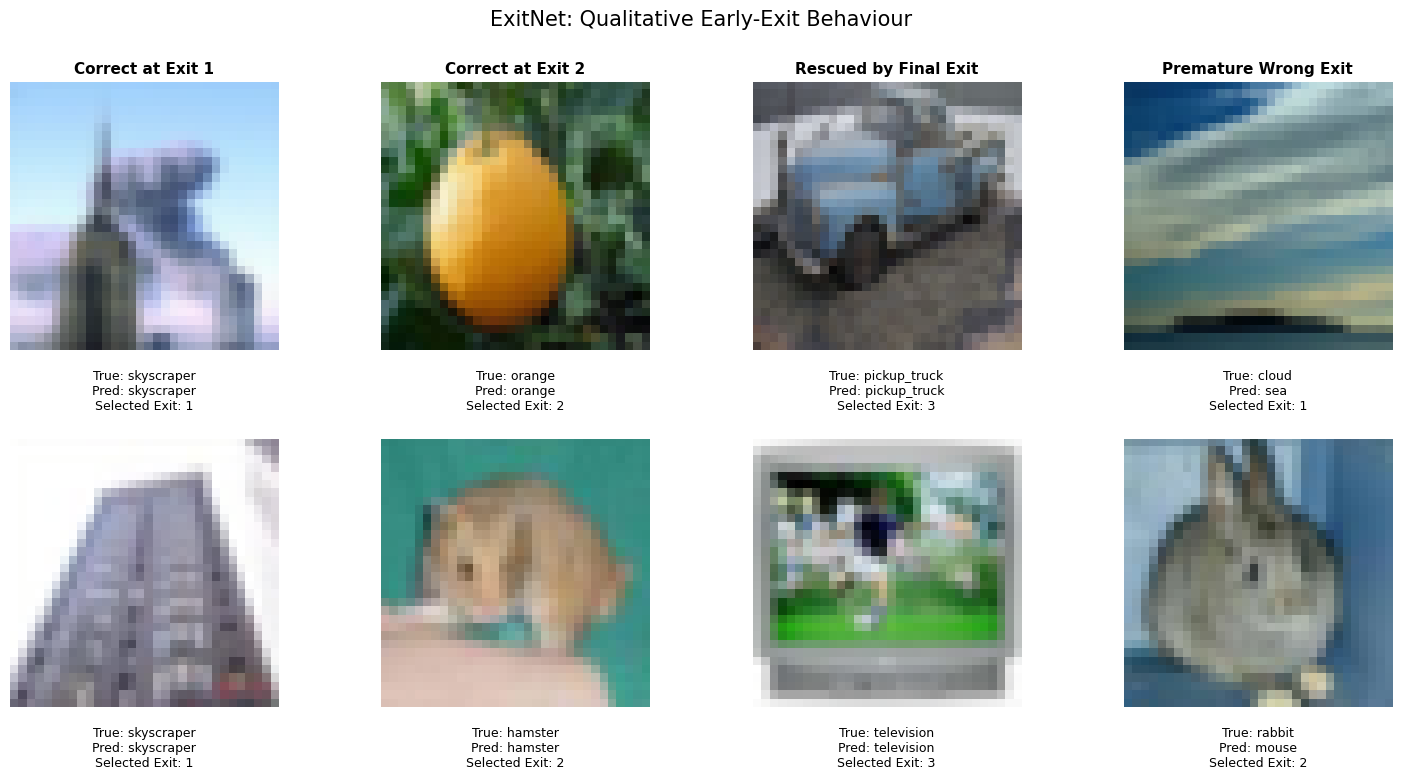


Saved figure: /content/drive/MyDrive/APS360_ExitNet/figures/exitnet_qualitative.png


In [ ]:

# Qualitative Evaluation of Learned Early Exits

# Use results from last to last cell:
# dynamic_predictions, dynamic_exits, val_labels
# Use individual exit predictions from Cell 13

categories = [
    (
        "Correct at Exit 1",
        (dynamic_exits == 0)
        & (dynamic_predictions == val_labels)
    ),
    (
        "Correct at Exit 2",
        (dynamic_exits == 1)
        & (dynamic_predictions == val_labels)
    ),
    (
        "Rescued by Final Exit",
        (dynamic_exits == 2)
        & (val_predictions[1] != val_labels)
        & (dynamic_predictions == val_labels)
    ),
    (
        "Premature Wrong Exit",
        (dynamic_exits < 2)
        & (dynamic_predictions != val_labels)
        & (val_predictions[2] == val_labels)
    )
]

rng = np.random.default_rng(SEED + 2026)

mean_tensor = torch.tensor(
    CIFAR100_MEAN, dtype=torch.float32
).view(3, 1, 1)

std_tensor = torch.tensor(
    CIFAR100_STD, dtype=torch.float32
).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

qualitative_records = []

for col, (category_name, mask) in enumerate(categories):

    candidate_indices = (
        torch.nonzero(mask, as_tuple=True)[0].numpy()
    )

    print(f"{category_name}: {len(candidate_indices)} samples")

    selected = rng.choice(
        candidate_indices,
        size=min(2, len(candidate_indices)),
        replace=False
    )

    for row in range(2):

        ax = axes[row, col]

        if row >= len(selected):
            ax.axis("off")
            continue

        idx = int(selected[row])

        # Validation image: deterministic preprocessing
        image, label = val_dataset[idx]

        # Reverse normalization for visualization
        image = image * std_tensor + mean_tensor
        image = image.clamp(0, 1)
        image = image.permute(1, 2, 0).numpy()

        pred = int(dynamic_predictions[idx])
        exit_id = int(dynamic_exits[idx]) + 1

        true_class = raw_train.classes[label]
        predicted_class = raw_train.classes[pred]

        ax.imshow(image)
        ax.axis("off")

        if row == 0:
            ax.set_title(
                category_name,
                fontsize=11,
                fontweight="bold"
            )

        ax.text(
            0.5, -0.07,
            f"True: {true_class}\n"
            f"Pred: {predicted_class}\n"
            f"Selected Exit: {exit_id}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9
        )

        qualitative_records.append({
            "category": category_name,
            "validation_index": idx,
            "true_class": true_class,
            "predicted_class": predicted_class,
            "selected_exit": exit_id
        })

plt.suptitle(
    "ExitNet: Qualitative Early-Exit Behaviour",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.03, 1, 0.96], h_pad=4)

figure_path = FIGURE_DIR / "exitnet_qualitative.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Save selected examples as a CSV
qualitative_df = pd.DataFrame(qualitative_records)

qualitative_df.to_csv(
    RESULT_DIR / "qualitative_examples.csv",
    index=False
)

print("\nSaved figure:", figure_path)

,policy,mean_ms,median_ms,std_ms,speedup_x
0,Confidence 0.60,13.663,11.539,23.445,0.919
1,Full-depth,12.557,9.568,15.496,1.000
2,Learned MLP 0.80,14.677,11.943,25.773,0.856



Mean paired latency differences vs full-depth:
Confidence 0.60: +1.106 ms (positive means slower)
Learned MLP 0.80: +2.120 ms (positive means slower)


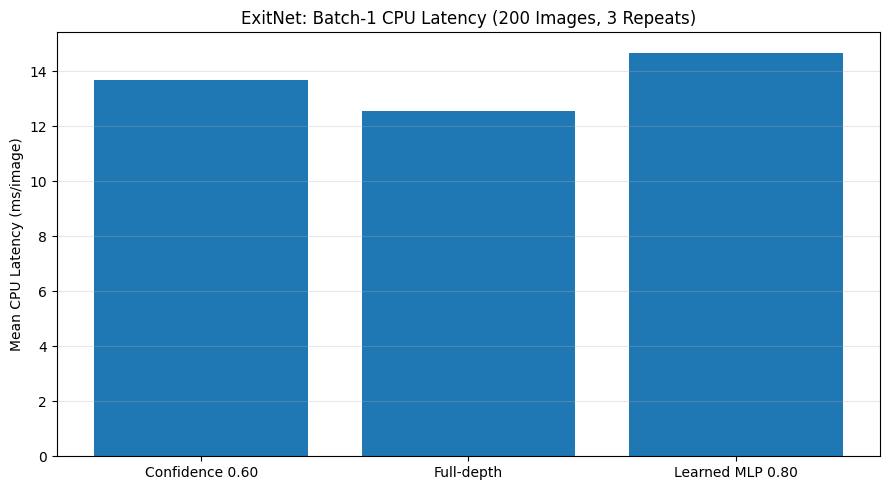


Benchmark results saved to Google Drive.


In [ ]:

# Repeated CPU Latency Benchmark

N_SAMPLES = 200
REPEATS = 3

rng = np.random.default_rng(SEED + 1001)

sample_ids = rng.choice(
    len(val_dataset),
    size=N_SAMPLES,
    replace=False
)

# Load images before timing, so data loading is excluded
samples = [
    val_dataset[int(i)][0].unsqueeze(0)
    for i in sample_ids
]

# Reuse CPU model copies from Cell 23
cpu_model.eval()
cpu_controller.eval()

policies = {
    "Full-depth": lambda x: full_depth_predict(
        cpu_model, x
    ),
    "Confidence 0.60": lambda x: dynamic_predict(
        cpu_model, x, threshold=0.60
    ),
    "Learned MLP 0.80": lambda x: dynamic_predict_controller(
        cpu_model, cpu_controller, x, threshold=0.80
    )
}

records = []

original_threads = torch.get_num_threads()

try:
    torch.set_num_threads(2)

    with torch.inference_mode():

        # Warm up every policy
        for name, fn in policies.items():
            for x in samples[:10]:
                fn(x)

        # Repeated paired measurements
        for repeat in range(REPEATS):

            for sample_id, x in zip(sample_ids, samples):

                # Randomize policy order to reduce
                # systematic timing-order effects
                policy_names = list(policies.keys())
                rng.shuffle(policy_names)

                for name in policy_names:

                    start = time.perf_counter()

                    policies[name](x)

                    elapsed_ms = (
                        time.perf_counter() - start
                    ) * 1000

                    records.append({
                        "repeat": repeat,
                        "sample_id": int(sample_id),
                        "policy": name,
                        "latency_ms": elapsed_ms
                    })

finally:
    torch.set_num_threads(original_threads)


# Summarize measurements

benchmark_df = pd.DataFrame(records)

summary_df = (
    benchmark_df
    .groupby("policy")["latency_ms"]
    .agg(
        mean_ms="mean",
        median_ms="median",
        std_ms="std"
    )
    .reset_index()
)

baseline_mean = summary_df.loc[
    summary_df["policy"] == "Full-depth",
    "mean_ms"
].iloc[0]

summary_df["speedup_x"] = (
    baseline_mean / summary_df["mean_ms"]
)

display(summary_df.round(3))


# Paired timing differences by sample

sample_means = (
    benchmark_df
    .groupby(["sample_id", "policy"])["latency_ms"]
    .mean()
    .unstack()
)

print("\nMean paired latency differences vs full-depth:")

for name in ["Confidence 0.60", "Learned MLP 0.80"]:

    differences = (
        sample_means[name]
        - sample_means["Full-depth"]
    )

    print(
        f"{name}: {differences.mean():+.3f} ms "
        "(positive means slower)"
    )


# Save results

benchmark_df.to_csv(
    RESULT_DIR / "cpu_latency_repeated_raw.csv",
    index=False
)

summary_df.to_csv(
    RESULT_DIR / "cpu_latency_repeated_summary.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    summary_df["policy"],
    summary_df["mean_ms"]
)

ax.set_ylabel("Mean CPU Latency (ms/image)")
ax.set_title(
    f"ExitNet: Batch-1 CPU Latency ({N_SAMPLES} Images, "
    f"{REPEATS} Repeats)"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cpu_latency_repeated.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nBenchmark results saved to Google Drive.")